# 05 · Ligando o grafo ao UNS ao vivo, e exportando para Neo4j

**Objetivo:** duas pontes.

1. **UNS → grafo:** o UNS sabe o **valor atual**; o grafo sabe **o que cada valor é**. O único campo que os une é `mfg:unsTopic`. Uma ponte escuta o broker e atualiza o grafo, criando eventos de mudança de estado.
2. **RDF → Neo4j:** o mesmo grafo convertido em Cypher, para quem usa grafo de propriedades.

Precisa de um broker MQTT em `localhost:1883` (`docker compose up -d`).

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
pd.set_option("display.max_colwidth", 80)
from lab.graph import load_ontology, load_plant, query, MFG, PRD, MNT, QA, NRG, INV, ID
import time, uuid
from lab.uns_bridge import UnsBridge, simulate_plant
from lab import queries as q
import socket
socket.create_connection(('localhost', 1883), timeout=2).close()
print('broker MQTT acessível em localhost:1883')

broker MQTT acessível em localhost:1883


## 1. Quantos tópicos o modelo conhece

In [2]:
g = load_plant()
ponte = UnsBridge(g, prefix=f"estudo-{uuid.uuid4().hex[:4]}")
print(f"{len(ponte.topic_to_dp)} tópicos modelados, por exemplo:")
for t in sorted(ponte.topic_to_dp)[:5]: print("  ", t)

30 tópicos modelados, por exemplo:
   acme/curitiba/packaging/line-3/capper-01/speed
   acme/curitiba/packaging/line-3/capper-01/state
   acme/curitiba/packaging/line-3/capper-01/temperature
   acme/curitiba/packaging/line-3/energy-meter/kwh
   acme/curitiba/packaging/line-3/filler-01/speed


## 2. Ligando a ponte e simulando 8 segundos de tráfego

O simulador publica estado, velocidade e temperatura das três enchedoras, e **também** uma tag `vibration_rms` que ninguém cadastrou no modelo.

In [3]:
ponte.start(); time.sleep(0.3)
simulate_plant(prefix=ponte.prefix, seconds=8)
time.sleep(0.5); ponte.stop()
print(f"mensagens recebidas      : {ponte.messages}")
print(f"eventos de estado criados: {ponte.events_added}")
print(f"tópicos órfãos           : {list(ponte.orphans)}")

mensagens recebidas      : 160
eventos de estado criados: 7
tópicos órfãos           : ['acme/sao-paulo/packaging/line-1/filler-01/vibration_rms']


**Leitura**

* Toda mensagem com tópico conhecido atualizou `lastValue` e `lastUpdate` no nó do ponto de dado.
* Cada **mudança** de estado virou um nó `StateChange` ligado à máquina: o histórico entra no modelo, não fica só no broker.
* `vibration_rms` é um **órfão**: existe no UNS mas não no modelo. Na prática é alguém que adicionou um sensor sem cadastrar o ativo. A ponte não descarta: registra, para alguém decidir se cadastra.

## 3. A mesma consulta do notebook 04, agora com valor ao vivo

In [4]:
pd.DataFrame(query(g, q.UNS_TOPICS_FOR_FILLERS))

,equipment,topic,value
0,Filler L3,acme/curitiba/packaging/line-3/filler-01/state,RUNNING
1,Filler L1,acme/sao-paulo/packaging/line-1/filler-01/state,STOPPED
2,Filler L2,acme/sao-paulo/packaging/line-2/filler-01/state,FAULTED


In [5]:
eventos = query(g, '''
SELECT ?maquina ?estado ?quando WHERE {
  ?e a mfg:StateChange ; mfg:toState ?estado ; mfg:startTime ?quando ; mfg:occurredOn/rdfs:label ?maquina .
} ORDER BY ?quando''')
pd.DataFrame(eventos).assign(quando=lambda d: pd.to_datetime(d.quando).dt.strftime("%H:%M:%S.%f").str[:12])

,maquina,estado,quando
0,Filler L1,RUNNING,20:05:18.754
1,Filler L2,RUNNING,20:05:18.755
2,Filler L3,RUNNING,20:05:18.755
3,Filler L1,STOPPED,20:05:19.252
4,Filler L2,FAULTED,20:05:19.753
5,Filler L3,FAULTED,20:05:22.758
6,Filler L3,RUNNING,20:05:23.258


Os eventos estão ligados à **máquina**, que está ligada à linha, à planta, às ordens e às paradas. Uma pergunta como "a enchedora da linha 1 entrou em FAULTED durante qual corrida, consumindo qual lote de tampa?" fica a uma consulta de distância.

## 4. Exportando para Neo4j (Cypher)

Mapeamento usado: cada recurso com tipo vira um **nó** com o nome da classe como label, literais viram **propriedades**, e relações entre recursos viram **arestas** em `MAIÚSCULAS`.

In [6]:
from lab.to_cypher import to_cypher
linhas = to_cypher(load_plant(with_ontology=False))
print(f"{len(linhas)} comandos Cypher\n")
for l in [linhas[0], linhas[1], linhas[60]] + [x for x in linhas if "CAUSED_BY" in x][:1] + [x for x in linhas if "CONSUMED" in x][:1]:
    print(l[:230]); print()

249 comandos Cypher

CREATE CONSTRAINT node_iri IF NOT EXISTS FOR (n:Resource) REQUIRE n.iri IS UNIQUE;

MERGE (n:Resource:Enterprise {iri: 'https://w3id.org/industrial-ontology-lab/id/acme'}) SET n.name = 'ACME Beverages', n.assetId = 'acme';

MERGE (n:Resource:Downtime {iri: 'https://w3id.org/industrial-ontology-lab/id/downtime/D-005'}) SET n.endTime = datetime('2026-11-10T13:42:00+00:00'), n.startTime = datetime('2026-11-10T13:35:00+00:00'), n.planned = false;

MATCH (a:Resource {iri: 'https://w3id.org/industrial-ontology-lab/id/downtime/D-001'}), (b:Resource {iri: 'https://w3id.org/industrial-ontology-lab/id/failure-mode/seal-wear'}) MERGE (a)-[:CAUSED_BY]->(b);

MATCH (a:Resource {iri: 'https://w3id.org/industrial-ontology-lab/id/run/R-1041'}), (b:Resource {iri: 'https://w3id.org/industrial-ontology-lab/id/material-lot/ML-2207'}) MERGE (a)-[:CONSUMED]->(b);



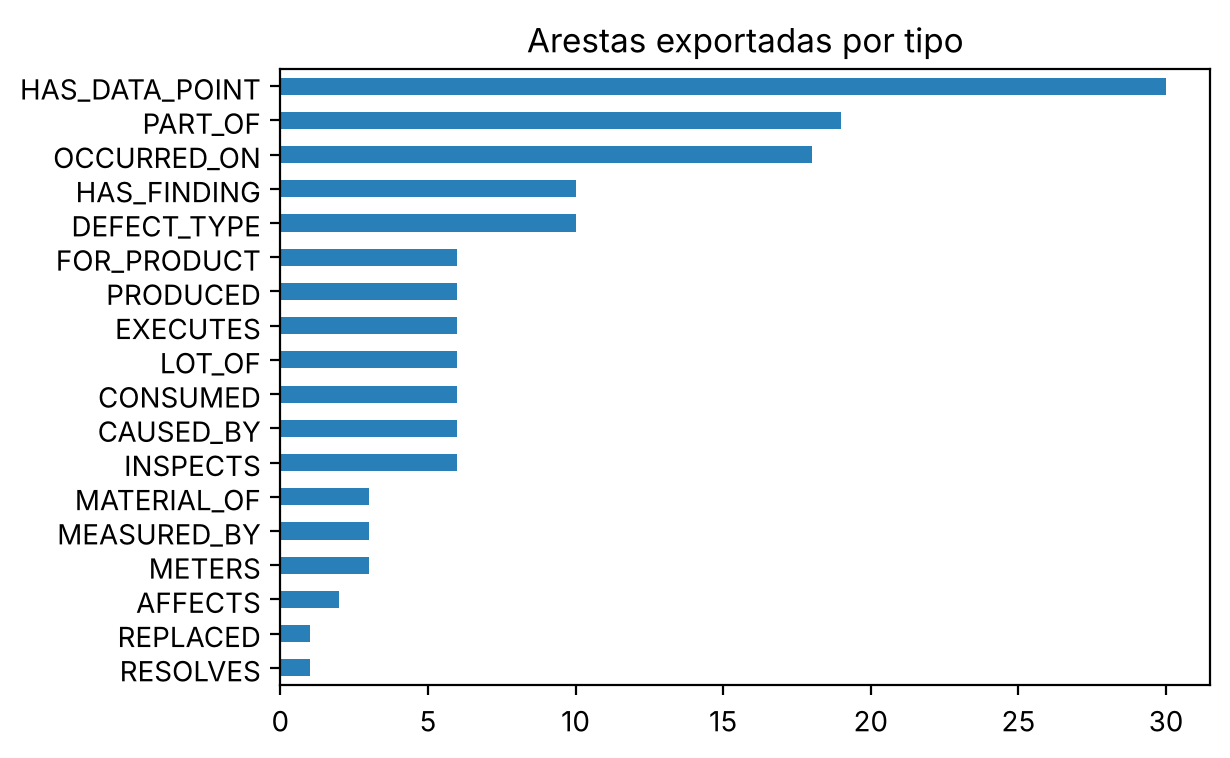

In [7]:
from collections import Counter
rels = Counter(l.split("-[:")[1].split("]")[0] for l in linhas if "-[:" in l)
pd.Series(rels).sort_values().plot.barh(figsize=(6, 4), color="#2980b9", title="Arestas exportadas por tipo"); import matplotlib.pyplot as plt; plt.show()

O arquivo pronto está em `neo4j/plant.cypher`. Para carregar: `docker compose -f neo4j/docker-compose.yml up -d`, abrir http://localhost:7474 e colar o arquivo, ou `cypher-shell -f neo4j/plant.cypher`. A mesma pergunta da seção 5 do notebook 04, em Cypher, está em `neo4j/queries.cypher`.

**RDF ou Neo4j?**

| | RDF + SPARQL | Neo4j + Cypher |
|---|---|---|
| Esquema e regras | OWL e SHACL padronizados | convenções do projeto |
| Identidade | IRIs globais, fáceis de juntar entre sistemas | ids locais |
| Consultas de caminho | property paths | padrões visuais, muito legíveis |
| Ecossistema de aplicação | menor | maior, com visualização pronta |

Uma combinação comum: modelar e validar em RDF, publicar para aplicações em Neo4j.

## Resumo

* O **tópico do UNS é a chave** entre o mundo ao vivo e o mundo semântico.
* Eventos de estado gravados no grafo herdam todo o contexto da máquina.
* Tópicos órfãos são um indicador de governança: dados que existem sem significado.
* O modelo é independente da tecnologia: o mesmo grafo vira Cypher com um script.